# 1. Setup

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("../data/raw/online_retail_II.csv")

In [3]:
def clean_data(data):
    df = data.dropna()
    df = df.drop_duplicates()
    df = df[df["Price"] > 0]
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    return df

In [4]:
data = clean_data(data)

# 2. Churn Definition

In [5]:
CUTOFF = pd.Timestamp("2011-09-09")

A customer is labeled as **churned (1)** if they made at least one purchase before the cutoff date (2011-09-09) but made **no purchase in the following 90 days** (2011-09-09 to 2011-12-09). Otherwise they are labeled **active (0)**.

- **Features** are built only from data *before* the cutoff.
- **Labels** come only from the 90 days *after* the cutoff.

This prevents data leakage: the model predicts future behavior using only past information.

In [6]:
def build_labels(data,cutoff):
    before_cutoff = data[data["InvoiceDate"] < cutoff]
    after_cut_off = data[data["InvoiceDate"] > cutoff]

    before_customer = before_cutoff["Customer ID"].unique()
    after_customer = after_cut_off["Customer ID"].unique()
    
    label = pd.DataFrame({"Customer ID":before_customer})
    label["returned"] = label["Customer ID"].isin(after_customer).astype(int)
    return label

In [7]:
labels = build_labels(data,CUTOFF)

In [8]:
labels['returned'].value_counts()

returned
0    3013
1    2328
Name: count, dtype: int64

# 3. Feature Engineering

In [9]:
def build_features(data, cutoff):
    before_cutoff = data[data["InvoiceDate"] < cutoff]

    first_purchase = before_cutoff.groupby("Customer ID")["InvoiceDate"].min()
    last_purchase = before_cutoff.groupby("Customer ID")["InvoiceDate"].max()

    before_cutoff = before_cutoff.copy()
    before_cutoff["revenue"] = before_cutoff["Quantity"] * before_cutoff["Price"]

    features = pd.DataFrame()
    features["recency"] = (cutoff - last_purchase).dt.days
    features["tenure"] = (cutoff - first_purchase).dt.days
    features["frequency"] = before_cutoff.groupby("Customer ID")["Invoice"].nunique()
    features["monetary"] = before_cutoff.groupby("Customer ID")["revenue"].sum()

    features["avg_order_value"] = features["monetary"] / features["frequency"]

    recent = before_cutoff[before_cutoff["InvoiceDate"] >= cutoff - pd.Timedelta(days=90)]
    features["recent_orders"] = recent.groupby("Customer ID")["Invoice"].nunique()
    features["recent_orders"] = features["recent_orders"].fillna(0)

    is_cancel = before_cutoff["Invoice"].astype(str).str.startswith("C")
    cancels = before_cutoff[is_cancel].groupby("Customer ID")["Invoice"].nunique()
    features["return_rate"] = (cancels / features["frequency"]).fillna(0)

    features["unique_products"] = before_cutoff.groupby("Customer ID")["StockCode"].nunique()

    span = (last_purchase - first_purchase).dt.days
    features["avg_days_between"] = (span / (features["frequency"] - 1)).fillna(0)

    features = features.reset_index()
    return features

In [10]:
features = build_features(data,CUTOFF)

In [11]:
def merge(lables,features):
    data = features.merge(lables,on = "Customer ID")
    return data

In [12]:
dataset = merge(labels,features)

In [13]:
dataset

,Customer ID,recency,tenure,frequency,monetary,avg_order_value,recent_orders,return_rate,unique_products,avg_days_between,returned
0,12346.0,233,633,17,-51.74,-3.043529,0.0,0.294118,30,25.000000,0
1,12347.0,37,312,6,3402.39,567.065000,1.0,0.000000,107,54.800000,1
2,12348.0,156,346,4,1709.40,427.350000,0.0,0.000000,25,63.000000,1
3,12349.0,315,643,4,2646.99,661.747500,0.0,0.250000,92,109.000000,1
4,12350.0,218,218,1,334.40,334.400000,0.0,0.000000,17,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...
5336,18283.0,3,566,16,1706.20,106.637500,5.0,0.000000,285,37.466667,1
5337,18284.0,337,339,2,436.68,218.340000,0.0,0.500000,28,2.000000,0
5338,18285.0,568,568,1,427.00,427.000000,0.0,0.000000,12,0.000000,0
5339,18286.0,384,631,3,1188.43,396.143333,0.0,0.333333,67,123.500000,0


# 4. Split Train/Test 

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
def split_xy(dataset):
    x = dataset.drop(columns=["returned", "Customer ID"])    
    y = dataset["returned"]

    return x,y

In [16]:
x,y = split_xy(dataset)

In [17]:
def split_train_test(x,y):
    X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2,stratify=y ,random_state = 42)
    return X_train,X_test,y_train,y_test

In [18]:
X_train,X_test,y_train,y_test = split_train_test(x,y)

# 5. Modelling

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

In [20]:
def train_model(x_train, y_train, model):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("Model", model)])
    pipeline.fit(x_train, y_train)
    return pipeline

In [21]:
def evaluate(pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    print("Accuracy:", acc)
    print("ROC-AUC:", auc)
    print(classification_report(y_test, y_pred))

    return {"accuracy": acc, "roc_auc": auc}

In [22]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1),
    "XGBoost": XGBClassifier(random_state=42),
}
 
results = {}

for name, model in models.items():
    print(f"\n===== {name} =====")
    pipeline = train_model(X_train, y_train, model)
    scores = evaluate(pipeline, X_test, y_test)
    results[name] = scores

results_df = pd.DataFrame(results).T.sort_values("roc_auc", ascending=False)
results_df


===== Logistic Regression =====
Accuracy: 0.7362020579981291
ROC-AUC: 0.8057957707884041
              precision    recall  f1-score   support

           0       0.74      0.81      0.78       603
           1       0.72      0.64      0.68       466

    accuracy                           0.74      1069
   macro avg       0.73      0.73      0.73      1069
weighted avg       0.74      0.74      0.73      1069


===== Random Forest =====
Accuracy: 0.7333956969130028
ROC-AUC: 0.7966070932889202
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       603
           1       0.73      0.61      0.67       466

    accuracy                           0.73      1069
   macro avg       0.73      0.72      0.72      1069
weighted avg       0.73      0.73      0.73      1069


===== Gradient Boosting =====
Accuracy: 0.7483629560336763
ROC-AUC: 0.8218830739008819
              precision    recall  f1-score   support

           0       0.75      

,accuracy,roc_auc
Gradient Boosting,0.748363,0.821883
LightGBM,0.727783,0.812228
Logistic Regression,0.736202,0.805796
Random Forest,0.733396,0.796607
XGBoost,0.718428,0.794379


# 6.Tune

In [23]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

In [28]:
def tune_model(X_train, y_train):
    param_grid = {
        "Model__n_estimators": [100, 200, 300],
        "Model__learning_rate": [0.01, 0.05, 0.1],
        "Model__max_depth": [2, 3, 4],
        "Model__subsample": [0.8, 1.0],
    }

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("Model", GradientBoostingClassifier(random_state=42))
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1
    )
    grid.fit(X_train, y_train)

    print("Best params:", grid.best_params_)
    print("Best CV ROC-AUC:", grid.best_score_)

    return grid.best_estimator_

In [29]:
best_model = tune_model(X_train, y_train)
evaluate(best_model, X_test, y_test)

Best params: {'Model__learning_rate': 0.01, 'Model__max_depth': 3, 'Model__n_estimators': 300, 'Model__subsample': 0.8}
Best CV ROC-AUC: 0.808552140364249
Accuracy: 0.744621141253508
ROC-AUC: 0.8205058398992164
              precision    recall  f1-score   support

           0       0.75      0.83      0.79       603
           1       0.74      0.64      0.68       466

    accuracy                           0.74      1069
   macro avg       0.74      0.73      0.73      1069
weighted avg       0.74      0.74      0.74      1069



{'accuracy': 0.744621141253508, 'roc_auc': 0.8205058398992164}

# 7. Model Analysis

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

In [32]:
def analyze_model(model, X_test, y_test):
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    # 1. feature importance
    importances = model.named_steps["Model"].feature_importances_
    imp = pd.Series(importances, index=X_test.columns).sort_values()
    ax[0].barh(imp.index, imp.values)
    ax[0].set_title("Feature importance")

    # 2. confusion matrix
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["Churned (0)", "Returned (1)"],
        ax=ax[1], cmap="Blues"
    )
    ax[1].set_title("Confusion matrix")

    plt.tight_layout()
    plt.show()

    return imp.sort_values(ascending=False)

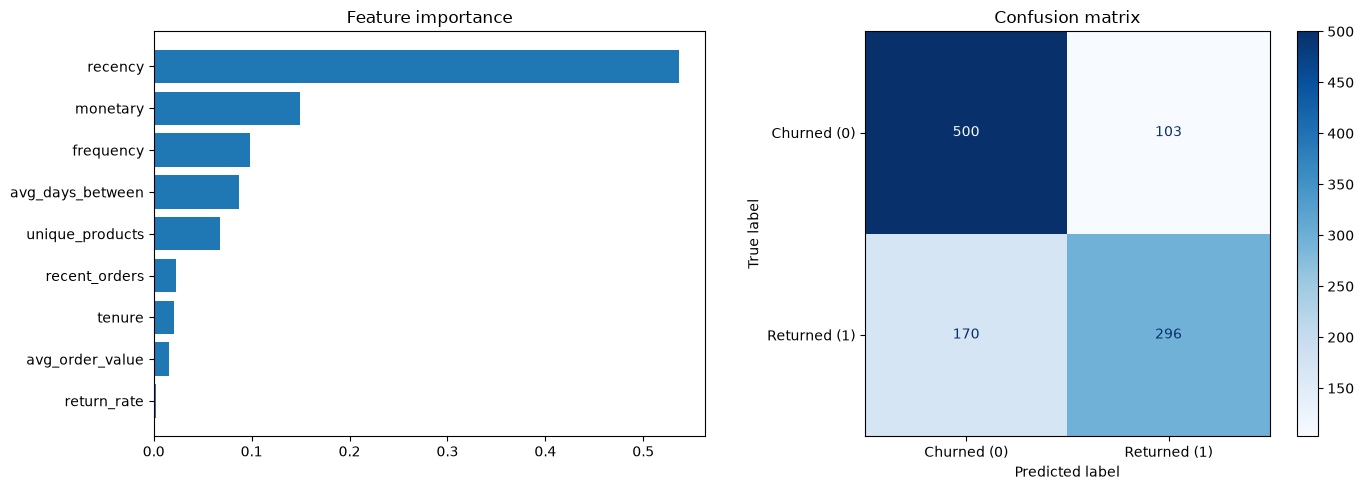

recency             0.536495
monetary            0.149632
frequency           0.098372
avg_days_between    0.086602
unique_products     0.067416
recent_orders       0.022584
tenure              0.020473
avg_order_value     0.016069
return_rate         0.002357
dtype: float64

In [33]:
analyze_model(best_model, X_test, y_test)

### 7.1 Feature Importance

| Feature | Importance |
|---|---|
| recency | 0.54 |
| monetary | 0.15 |
| frequency | 0.10 |
| avg_days_between | 0.09 |
| unique_products | 0.07 |
| recent_orders | 0.02 |
| tenure | 0.02 |
| avg_order_value | 0.02 |
| return_rate | 0.00 |

- **Recency dominates** (over half of the model's decisions): how long ago a customer last bought is by far the strongest signal of whether they will come back.
- **Monetary and frequency** come next: customers who spend more and order more often are more likely to return.
- **avg_days_between and unique_products** add useful detail about buying rhythm and engagement breadth.
- **recent_orders** has low importance, likely because it overlaps with recency (both measure recent activity), so the model gets that information from recency already.
- **return_rate** contributes almost nothing: past cancellations do not help predict churn in this dataset.

### 7.2 Confusion Matrix

| | Predicted churned | Predicted returned |
|---|---|---|
| **Actually churned** | 500 ✅ | 103 ❌ |
| **Actually returned** | 170 ❌ | 296 ✅ |

- The model correctly identifies **500 of 603 churners (83% recall)**.
- **103 churners are missed**: the model thinks they will return, but they do not. This is the costlier error, since these customers would receive no retention effort.
- **170 returning customers are flagged as churners**: they might receive an unnecessary retention offer. This error is cheaper (a discount sent to an already loyal customer).

### 7.3 Business Takeaway

The model is well suited to a retention use case: it catches most at-risk customers, at the cost of some false alarms. Since **recency** is the key driver, a simple rule like "contact customers inactive for X days" would capture much of the value, while the model refines this by also considering spending, frequency, and buying rhythm.

In [36]:
import joblib
import os

In [ ]:
os.makedirs("../models",exist_ok = True)